# Create impact projection files
In same format as BCD-ME inputs, one zarr per GCM (per impact). Can think about concatenating them afterwards

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import zarr
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar

import distributed

from funcs_support import get_filepaths,get_params,utility_save
from funcs_readregs import coeffs_mortality, coeffs_gdppc, coeffs_payroll
dir_list = get_params()

In [2]:
from distributed import Client

# Start dask client 
# (playing around with workers, threads for efficiency)
client = Client(n_workers=6,
    threads_per_worker=3,
    processes=True,
    memory_limit="8GB")
display(client)

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/climate/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/climate/proxy/8787/status,Workers: 6
Total threads: 18,Total memory: 44.70 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44093,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/climate/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:34993,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/climate/proxy/35373/status,Memory: 7.45 GiB
Nanny: tcp://127.0.0.1:40329,


## Default settings
(pooled regression for mortality, etc.) 

(maybe will want to concat alternate projections under a sepcification-specific dimension in the same zarrs)

In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','popwght':True},
               'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','popwght':True}}

In [4]:
overwrite = False

for proc in params_proc:
    # Get filenames of aggregated climate predictors
    fns = np.sort(glob.glob(f'{dir_list['proc']}aggs/{params_proc[proc]['varname']}_*_{params_proc[proc]['geo_typ']}*'))
    if params_proc[proc]['popwght']:
        fns = [fn for fn in fns if re.search(r'\_popwght\.zarr',fn)]
    else:
        fns = [fn for fn in fns if not re.search(r'\_popwght\.zarr',fn)]
    fns = {re.split(r'\_',re.split(r'\/',fn)[-1])[2]:fn for fn in fns}
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc()
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality()
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll()
    else:
        raise KeyError()
    
    for mod in tqdm(fns):
        output_fn = f'{dir_list['proc']}impact_projs/{proc}/{re.sub(params_proc[proc]['varname'],f'd{proc}',re.split(r'\/',fns[mod])[-1])}'
        
        if overwrite or (not os.path.exists(output_fn)):
            
            # Load aggregated climate predictor
            ds = xr.open_zarr(fns[mod],consolidated=False,decode_timedelta=False)
        
            # Isolate predictor variables
            if params_proc[proc]['varname'] == 'tassumpoly':
                ds['degree'] = [f'tassumpoly_{k}' for k in ds.degree.values]
                ds = ds.rename({'degree':'pred'})
            elif params_proc[proc]['varname'] == 'tasmaxbinF':
                ds['binF'] = [f'tasmaxbinF_{k}' for k in ds.binF.values]
                ds = ds.rename({'binF':'pred'})
            else:
                raise KeyError()
        
            # Calculate impact from linear regression model
            ds[proc] = (coeffs.coeffs*ds[params_proc[proc]['varname']]).sum('pred',skipna=False)
            # Calculate change in impact vs. GWL0.61
            ds['d'+proc] = ds[proc] - ds[proc].sel(gwl=0.61)

            # Add max gwl to coordinates, for referece
            ds = ds.assign_coords({'maxgwl':(('idv'),ds.gwl.isel(gwl=np.array([g if g != 0 else -1 
                                                              for g in (np.isnan(ds['d'+proc]).
                                                                        argmax('gwl').
                                                                        max([d for d in ds['d'+proc].sizes if d not in ['gwl','idv']])).
                                                                        load()])).values)})
        
            # Prepare output 
            ds_out = ds[['locid','d'+proc]]
            ds_out.attrs = {'SOURCE':'project_impacts.ipynb',
                    'DESCRIPTION':f'changes in {proc}, at the {params_proc[proc]['geo_typ']} level',
                    'pop_weighted':params_proc[proc]['popwght']}
        
            # Export
            with warnings.catch_warnings():
                # Catches a Zarr v3 error related to string coordinates saved 
                # as objects instead of strings, I believe
                warnings.filterwarnings('ignore')
                utility_save(ds_out,output_fn,zarr_mode='w',save_kwargs = {'zarr_format':3,'consolidated':False})
        else:
            print(output_fn+' exists, skipped!')

  0%|          | 0/12 [00:00<?, ?it/s]

/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality/dmortality_agg_ACCESS-ESM1-5_ALLRUNS_ALLGWLs_impact-regions.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality/dmortality_agg_CESM2-WACCM_ALLRUNS_ALLGWLs_impact-regions.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality/dmortality_agg_CNRM-CM6-1_ALLRUNS_ALLGWLs_impact-regions.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality/dmortality_agg_CNRM-ESM2-1_ALLRUNS_ALLGWLs_impact-regions.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality/dmortality_agg_CanESM5_ALLRUNS_ALLGWLs_impact-regions.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/mortality/dmortality_agg_EC-Earth3-Veg_ALLRUNS_ALLGWLs_impact-regions.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impac

  0%|          | 0/12 [00:00<?, ?it/s]

/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/gdppc/dgdppc_agg_ACCESS-ESM1-5_ALLRUNS_ALLGWLs_adm1_popwght.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/gdppc/dgdppc_agg_CESM2-WACCM_ALLRUNS_ALLGWLs_adm1_popwght.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/gdppc/dgdppc_agg_CNRM-CM6-1_ALLRUNS_ALLGWLs_adm1_popwght.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/gdppc/dgdppc_agg_CNRM-ESM2-1_ALLRUNS_ALLGWLs_adm1_popwght.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/gdppc/dgdppc_agg_CanESM5_ALLRUNS_ALLGWLs_adm1_popwght.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/gdppc/dgdppc_agg_EC-Earth3-Veg_ALLRUNS_ALLGWLs_adm1_popwght.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/gdppc/dgdppc_agg_EC-Earth3_ALLRUNS_ALLGWLs_adm1_popw

  0%|          | 0/11 [00:00<?, ?it/s]

...

/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/payroll/dpayroll_agg_MIROC6_ALLRUNS_ALLGWLs_adm2-us_popwght.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at .done is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/payroll/dpayroll_agg_MPI-ESM1-2-LR_ALLRUNS_ALLGWLs_adm2-us_popwght.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at .done is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/payroll/dpayroll_agg_MRI-ESM2-0_ALLRUNS_ALLGWLs_adm2-us_popwght.zarr saved!


In [133]:
nsamples = 1000
# Get monte carlo samples of the betas 

rng = np.random.default_rng()

coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
               coeffs.coeffs,
               vcv.vcv,
               input_core_dims = [['pred'],['pred_1','pred_2']],
               output_core_dims = [['sidx','pred']],
               kwargs = {'size':nsamples},
                       dask = 'parallelized',
                       dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
               vectorize=True)

In [134]:
coeffs_mvn.mean('sidx')

<xarray.DataArray 'coeffs' (proj_base: 4, pred: 4)> Size: 128B
array([[-2.09801961e-02, -7.42044804e-04,  1.01976108e-06,
         1.95340738e-06],
       [-1.16478963e-02, -1.94976165e-03,  4.36303885e-05,
         1.24357677e-06],
       [-1.45776223e-02, -1.67833981e-03, -6.03587631e-06,
         2.48940267e-06],
       [-8.15413389e-03, -1.56477852e-03, -3.94162050e-05,
         2.29439143e-06]])
Coordinates:
  * proj_base  (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
  * pred       (pred) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
    covar      <U1 4B '1'
    ageset     <U5 20B 'total'
    spectype   <U6 24B 'pooled'

In [136]:
ds[proc] = (coeffs_mvn*ds[params_proc[proc]['varname']]).sum('pred')
# Calculate change in impact vs. GWL0.61
ds['d'+proc] = ds[proc] - ds[proc].sel(gwl=0.61)

In [138]:
ds['dmortality']

<xarray.DataArray 'dmortality' (proj_base: 4, sidx: 1000, poly_idx: 24378,
                                idv: 12, gwl: 7)> Size: 66GB
dask.array<sub, shape=(4, 1000, 24378, 12, 7), dtype=float64, chunksize=(1, 1000, 24378, 1, 7), chunktype=numpy.ndarray>
Coordinates:
  * proj_base   (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
  * poly_idx    (poly_idx) int64 195kB 0 1 2 3 4 ... 24374 24375 24376 24377
  * idv         (idv) int64 96B 0 1 2 3 4 5 6 7 8 9 10 11
    experiment  (idv) <U6 288B dask.array<chunksize=(1,), meta=np.ndarray>
    run         (idv) <U8 384B dask.array<chunksize=(1,), meta=np.ndarray>
  * gwl         (gwl) float64 56B 0.61 1.0 1.5 2.0 2.5 3.0 3.5
    covar       <U1 4B '1'
    ageset      <U5 20B 'total'
    spectype    <U6 24B 'pooled'
Dimensions without coordinates: sidx

In [64]:
gdf = gpd.read_file('../aux_data/geo_data/country-fixed.shp')

In [66]:
gdf = gdf.rename({'CNTRY_NAME':'locid'},axis=1).set_index('locid')

In [67]:
from funcs_plot import plot_map

In [73]:
ds_out['poly_idx'] = ds_out['locid']

(array([17., 78., 61., 45., 35., 10.,  1.,  0.,  1.,  1.]),
 array([-13.60889741, -10.17975833,  -6.75061924,  -3.32148016,
          0.10765892,   3.53679801,   6.96593709,  10.39507618,
         13.82421526,  17.25335434,  20.68249343]),
 <BarContainer object of 10 artists>)

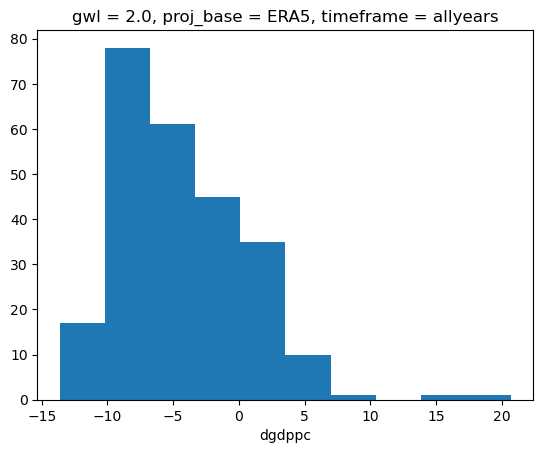

In [77]:
ds_out.dgdppc.sel(gwl=2,timeframe='allyears',proj_base='ERA5').mean('idv').sel(poly_idx = gdf.index.values).plot.hist()

In [79]:
import cmocean

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

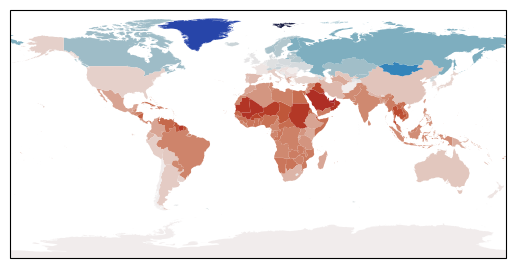

In [88]:
plot_map(ds_out.dgdppc.sel(gwl=2,timeframe='allyears',proj_base='ERA5').mean('idv').sel(poly_idx = gdf.index.values),
         gdf,vmin=-20,vmax=20,cmap=cmocean.cm.balance_r)

In [56]:
output_fn

'/glade/derecho/scratch/schwarzwald/impact_uncertainty/impact_projs/gdppc/dgdppc_agg_ACCESS-ESM1-5_ALLRUNS_ALLGWLs_adm1_popwght.zarr'